# Analysis of the dataset

## 0. Imports & Config

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import ipaddress
import urllib.parse
from sklearn import train_test_split

TEST_SIZE = 0.2
RANDOM_STATE = 42

DATASET_PATH = r"C:\Users\User\Documents\Key Future Docs\Projects\Phising URL\dataset\new_data_urls.csv"

## 1. Load the dataset

In [43]:
df = pd.read_csv(DATASET_PATH)

df.reset_index(drop=True, inplace=True)
df.rename(columns={"status": "is_phishing"}, inplace=True)
df['is_phishing'] = df['is_phishing'] == 1

print("Total number of URLs in the dataset: ", len(df))
df.sample(10, ignore_index=True).sort_values(by="is_phishing")

Total number of URLs in the dataset:  822010


,url,is_phishing
0,http://home.earthlink.net/~iiil.llii/in/zimbra...,False
1,https://www.micoadrio-jp.thgrmaz.cn,False
2,https://nfghcx.56bocc5.cn/,False
3,https://cranetech.com.br/SE/ec9933ff30188a72f8...,False
4,doiop.com/newupdatedamexmessage,False
6,https://54-224-205-117.cprapid.com/img/,False
8,https://www.amozon.atrocitees.com/jp.php,False
5,halloffameporn.com/porn-hall-of-fame.php,True
7,pipl.com/directory/name/Gordon/Lionel,True
9,lechateauevents.com/index.php,True


In [ ]:
num_phishing = df['is_phishing'].where(df['is_phishing'] == True).count()
num_legitimate = df['is_phishing'].where(df['is_phishing'] == False).count()
total = num_phishing + num_legitimate

print(f"The shape of the dataset is: {df.shape} with data types: {df.dtypes}")
print(f"Number of phishing URLs: {num_phishing}")
print(f"Number of legitimate URLs: {num_legitimate}")
print(f"Ratio of phishing to legitimate URLs: {num_phishing / num_legitimate:.4f} ({num_phishing}/{num_legitimate})")
print(f"Phishing to total ratio: {num_phishing / total:.4f}")
print(f"Number of URLs with NaN values: {df['url'].isnull().sum()}")
print(f"Number of labels with NaN values: {df['is_phishing'].isnull().sum()}")

The shape of the dataset is: (822010, 2) with data types: url            object
is_phishing      bool
dtype: object
Number of phishing URLs: 427028
Number of legitimate URLs: 394982
Number of URLs with NaN values: 0
Number of labels with NaN values: 0


## 2. Split train & test periods

In [ ]:
train_df, test_df = train_test_split(
    df,
    test_size=TEST_SIZE,
    random_state=RANDOM_STATE,
    stratify=df["is_phishing"], # to keep the same ratio of phishing and legitimate URLs in the train and test sets
)
print(f"Train size: {len(train_df)}")
print(f"Test size: {len(test_df)}")

## 3. Split URLs into protocols, domains and paths

Using: https://docs.python.org/3/library/urllib.parse.html

In [45]:
def is_ip(string):
    try:
        string = string.strip('[]')
        ipaddress.ip_address(string)
        return True
    except:
        return False

result = []
for i, row in train_df.iterrows():
    raw_url = row['url']
    is_ip_result = is_ip(raw_url)
    if '://' not in raw_url and not is_ip_result:
        raw_url = 'http://' + raw_url
    try:
        parsed_url = urllib.parse.urlparse(raw_url)
    except:
        print(f"Error parsing URL: {raw_url}")
        result.append([None, None, None, None, None, False])
        continue
    protocol = parsed_url.scheme
    domain = parsed_url.netloc
    subdomains = parsed_url.netloc.split('.')[:-1]
    path = parsed_url.path
    tld = parsed_url.netloc.split('.')[-1]
    result.append([protocol, domain, subdomains, path, tld, is_ip_result])

train_df = pd.concat([train_df, pd.DataFrame(result, columns=['protocol', 'domain', 'subdomains', 'path', 'tld', 'is_ip'])], axis=1)
train_df.dropna(inplace=True)
print(train_df["is_ip"].value_counts())
print(train_df.loc[train_df["is_ip"], "url"].head(10))
train_df.sample(10, ignore_index=True).sort_values(by="is_phishing")

Error parsing URL: http://RybjUxÙãl5»7ÆE%ÝÔk+h|U+ýk©ìÉ½Æq]âF·õÁ¢w)ëA·ç°{t*m!¦2
Error parsing URL: http://ÆeF§÷%¶¿Õ½9¿b@Ö¸ÚZE¤ÒC¢ÄÅª2åç-]W³fU¤Jgkz.ø¿nJçåæuøD%@ðûÇùM¹uË
Error parsing URL: http://Ó6¸RTÃu~æÙg0>÷mÖiÓ=;XZ\%êýÜÉfn&\°%7õÉ"ieÖ1ÄÁêFÐò<$cï6t[0ò2"/Æa^2âpù/ýãÇ$E¬R«È²ú[Ì¶p¥qÒ°i°^ò[»³»]±9êdÓS¿Ë]ùþ5j¿·ªocÂplà7ÊÏJ§¢#3ðDCDõ²çÇGÝ.Vò=¿QB§Ä'`ÊáZÉê ÔîÆm®ÍÝQÓ(z;¹Áê¬âytÖÙ®ëNP²ÜEQ
Error parsing URL: http://oÍÑOwEuÊÚÃß=nËß[j{2%.tñø­½½qx½NºPmx$Aì&ÝIhÂéc¶A9®cì3ßyiÚý~JÍf]$ö M¸°;xÃu0IÅ@xõe^cÃ ¸´ÞO7B~FrØ\<kÅb{T!Ìé	r?kX-YÇS@T)LeaÃ}°¡ùï4ºkïá2¢kEì¬ôfsçË×ÛQìê{o£UÜ§D©l½±±äâqôó¼-â0èÙ¦kvîdàQÎé6°Ò¼©
Error parsing URL: http://µÔA¨!ÝÛ=]º£¦Pôwr72-ÕY5Äòè7¬-³]×)&¡e¸¢À6RD­NvY¨Ð«Ñ3Â¸%Qñ+ÛÈ¸$¶gz{þ
Error parsing URL: http://¨RÊÃûaCóÞit×ßÂe-DÖØ+9YèÌçÏ¯·"0£ÙÕ.0ößF«7¹NRÙ{ccÉÄãéçx[Ä6a5Ñ³LÖíÜÉÀ£Òma¥yRX*0ÅÝ7×ÊÁÌo«Õs¶0kdèÑ&Ä"Ï¨mZ'àDM×ñXÚÒK"päî±h¬c

,url,is_phishing,protocol,domain,subdomains,path,tld,is_ip
0,https://khdvc.ku3fvwwpp.cn,False,https,khdvc.ku3fvwwpp.cn,"[khdvc, ku3fvwwpp]",,cn,False
3,service.confirms.paypal.cmd.cgi-bins.2466sd4f3...,False,http,service.confirms.paypal.cmd.cgi-bins.2466sd4f3...,"[service, confirms, paypal, cmd, cgi-bins, 246...",/pp/,com,False
4,https://plain-forest-6e21.tbo6tn5q.workers.dev/,False,https,plain-forest-6e21.tbo6tn5q.workers.dev,"[plain-forest-6e21, tbo6tn5q, workers]",/,dev,False
5,https://cxvczx.yo14lx97z.cn,False,https,cxvczx.yo14lx97z.cn,"[cxvczx, yo14lx97z]",,cn,False
1,genforum.genealogy.com/bourcier/,True,http,genforum.genealogy.com,"[genforum, genealogy]",/bourcier/,com,False
2,https://www.careercup.com/salary,True,https,www.careercup.com,"[www, careercup]",/salary,com,False
6,haro-online.com/movies/kid_stays_in_the_pictur...,True,http,haro-online.com,[haro-online],/movies/kid_stays_in_the_picture.html,com,False
7,census-info.us/show/DAIGLE/,True,http,census-info.us,[census-info],/show/DAIGLE/,us,False
8,augustevening.com/,True,http,augustevening.com,[augustevening],/,com,False
9,thefreelibrary.com/KINGS+NOTEBOOK%3b+GOOD+NEWS...,True,http,thefreelibrary.com,[thefreelibrary],/KINGS+NOTEBOOK%3b+GOOD+NEWS%2c+ROTTEN+NEWS%3b...,com,False


# 4. Search for patterns in the dataset

In [ ]:
def create_bar_plot(df_temp, column, title, limit_x=None, limit_y=None):
    phishing_counts = df_temp.where(df_temp['is_phishing'] == True).groupby(column)['is_phishing'].count()
    legitimate_counts = df_temp.where(df_temp['is_phishing'] == False).groupby(column)['is_phishing'].count()

    ratio = legitimate_counts / (phishing_counts + legitimate_counts)

    ax = ratio.plot(kind='bar', figsize=(10, 5))
    if limit_x is not None:
        ax.set_xlim(0, limit_x)
    if limit_y is not None:
        ax.set_ylim(0, limit_y)
    ax.axhline(1, color='gray', linestyle='--', linewidth=1)
    plt.title(title)
    plt.xlabel(column)
    plt.ylabel('% legitimate')
    plt.show()

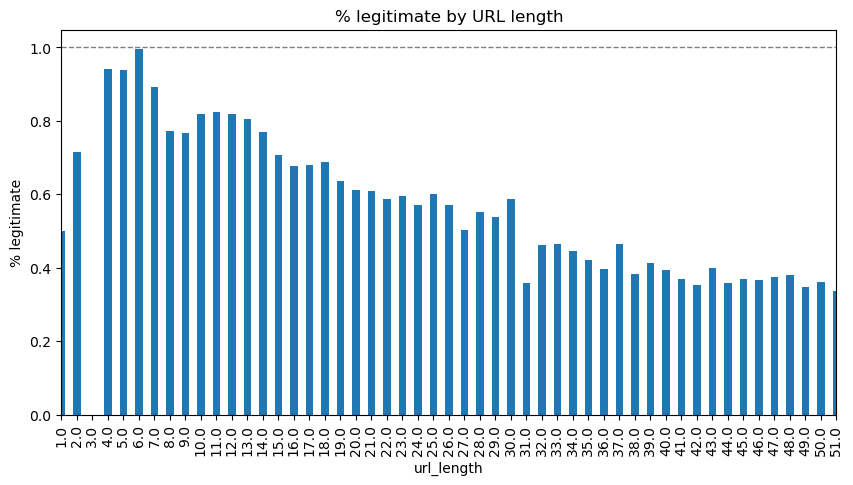

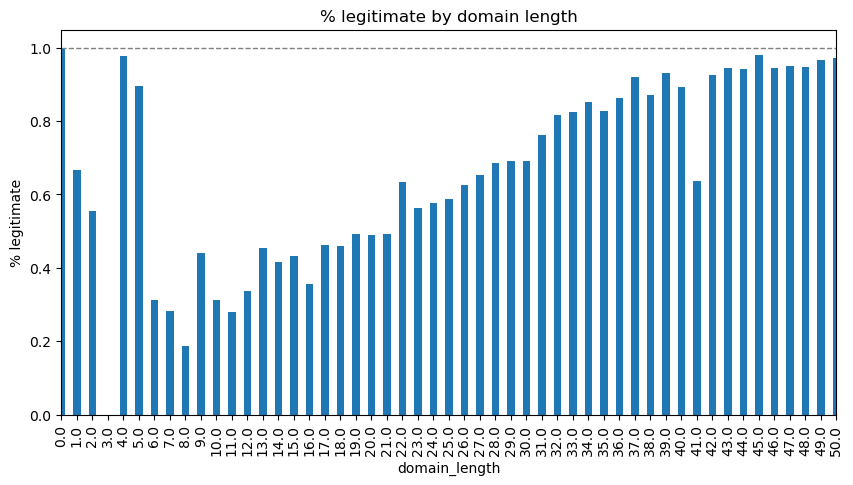

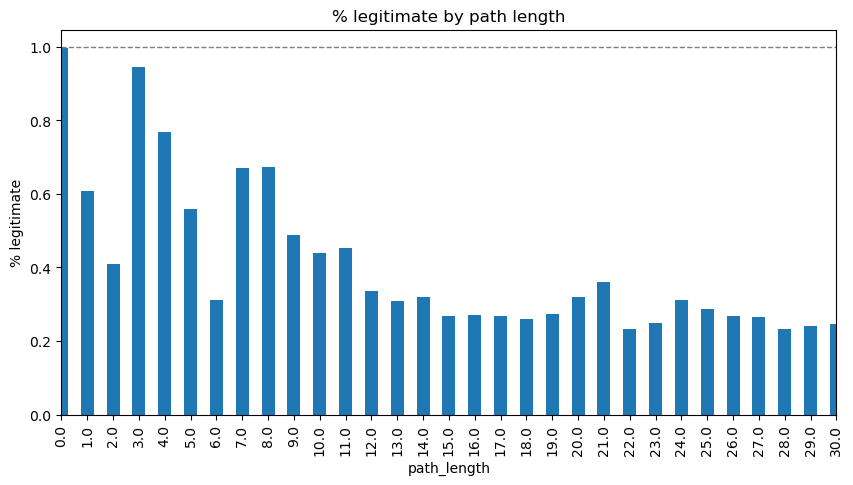

In [47]:
length_plots = train_df.copy()
length_plots['url_length'] = length_plots['url'].str.len()
create_bar_plot(length_plots, 'url_length', '% legitimate by URL length', 50)

length_plots['domain_length'] = length_plots['domain'].str.len()
create_bar_plot(length_plots, 'domain_length', '% legitimate by domain length', 50)

length_plots['path_length'] = length_plots['path'].str.len()
create_bar_plot(length_plots, 'path_length', '% legitimate by path length', 30)

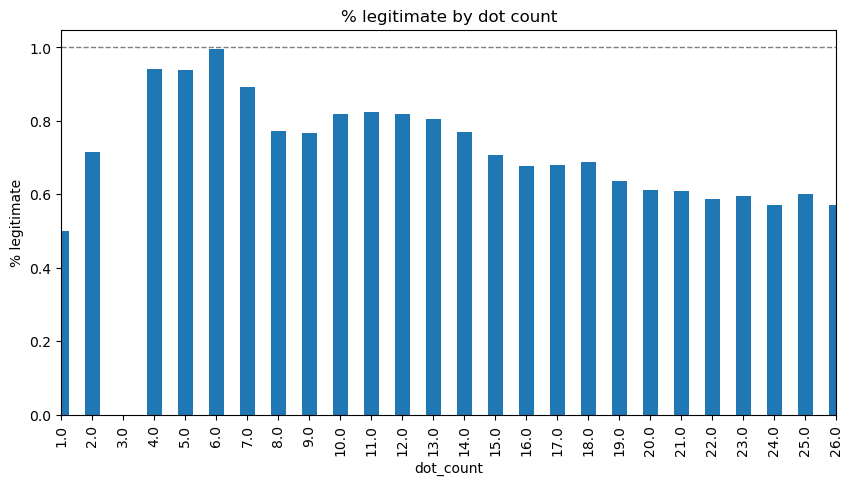

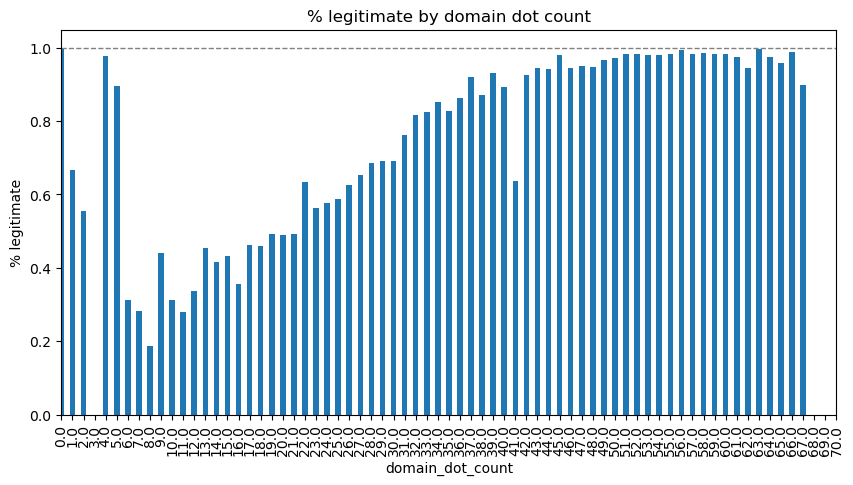

In [48]:
dot_plots = train_df.copy()
dot_plots['dot_count'] = dot_plots['url'].str.count('.')
create_bar_plot(dot_plots, 'dot_count', '% legitimate by dot count', 25)

# per section dot count
dot_plots['domain_dot_count'] = dot_plots['domain'].str.count('.')
create_bar_plot(dot_plots, 'domain_dot_count', '% legitimate by domain dot count', 70)

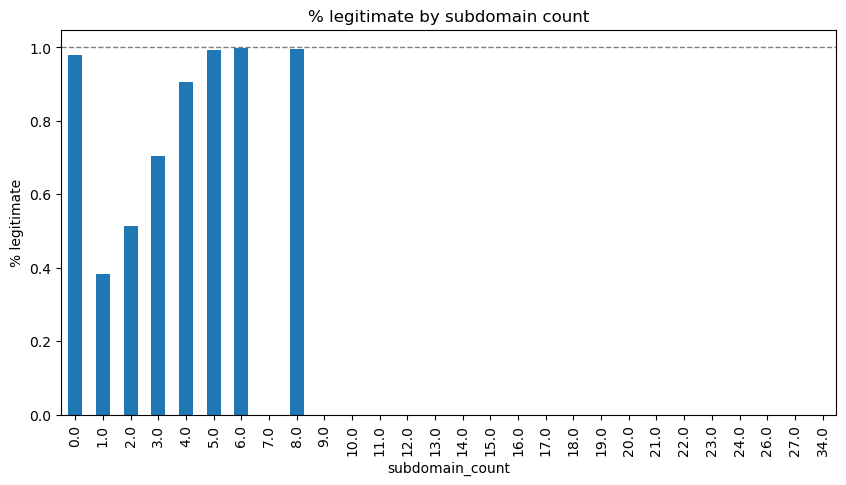

In [49]:
subdomain_plot = train_df.copy()
subdomain_plot['subdomain_count'] = subdomain_plot['subdomains'].str.len()
create_bar_plot(subdomain_plot, 'subdomain_count', '% legitimate by subdomain count')

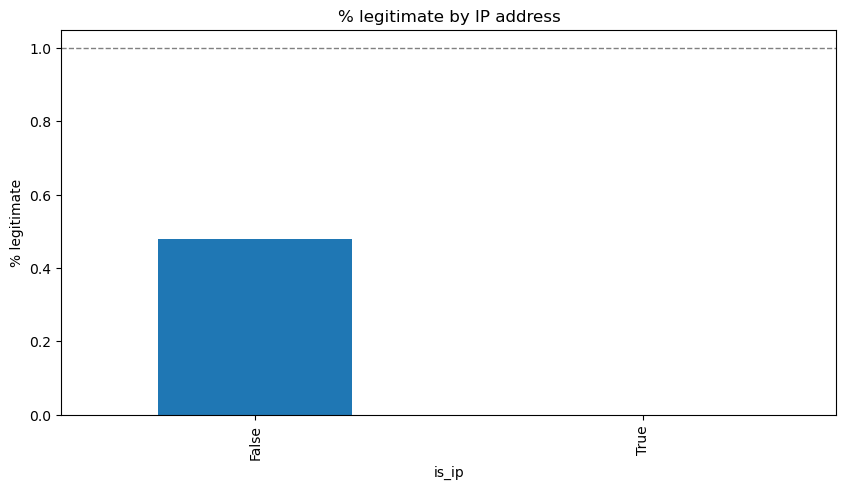

In [50]:
ip_plot = train_df.copy()
create_bar_plot(ip_plot, 'is_ip', '% legitimate by IP address')

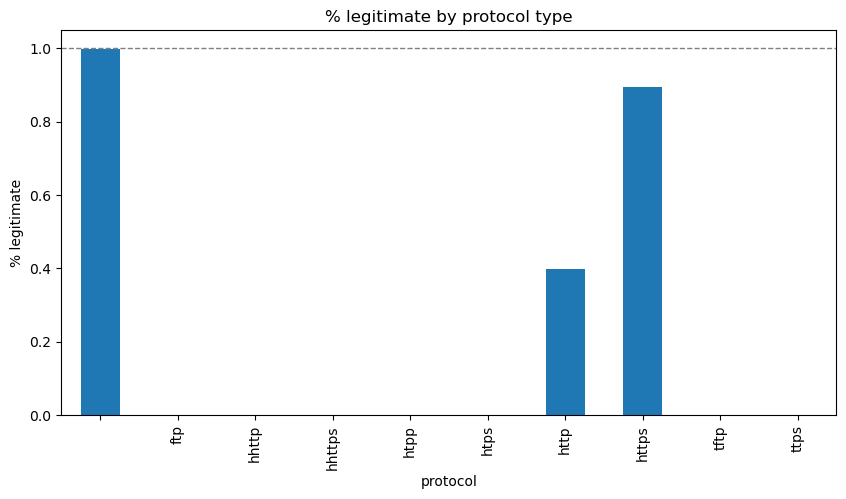

In [ ]:
protocol_type_plot = train_df.copy()
protocol_type_plot = protocol_type_plot[~protocol_type_plot['protocol'].str.endswith('xxp', na=False)] # dropping a long incorrect protocol
create_bar_plot(protocol_type_plot, 'protocol', '% legitimate by protocol type')

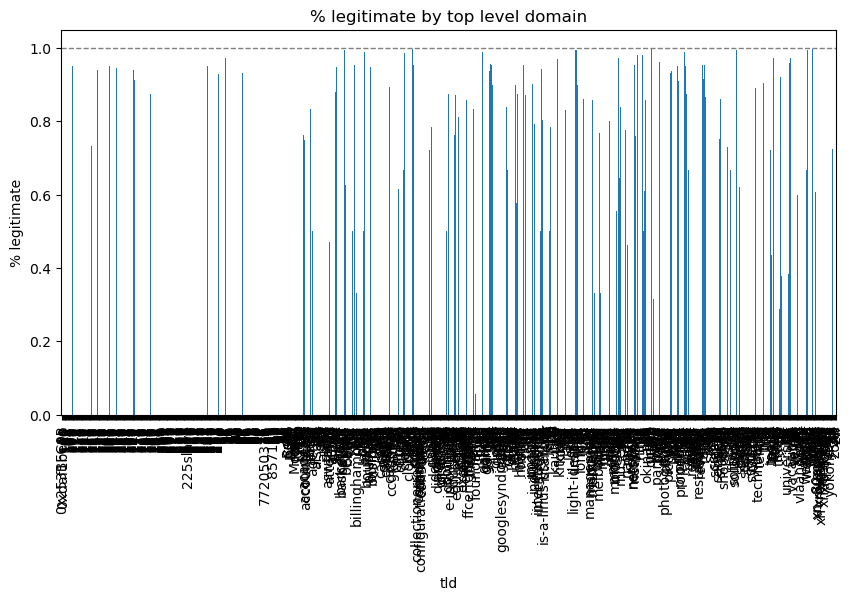

In [53]:
top_level_domain_plot = train_df.copy()
top_level_domain_plot = train_df[train_df['tld'].astype(str).str.fullmatch(r'[A-Za-z0-9-]{2,24}')]
create_bar_plot(top_level_domain_plot, 'tld', '% legitimate by top level domain')